In [1]:
#Import the libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Read the dataset
original_DF = pd.read_csv('heart.csv')

In [ ]:
#Display the first few records
original_DF.head()

In [ ]:
#Display number of rows and columns 
original_DF.shape

In [ ]:
#Display the data types of each column
original_DF.dtypes

In [ ]:
#Display the summary statistics of the dataset
original_DF.describe(include='all')

In [3]:
#Checking duplicate rows
exact_duplicates = original_DF.duplicated().sum()
print(f"Number of exact duplicate rows: {exact_duplicates}")

Number of exact duplicate rows: 723


In [4]:
#Removing duplicate rows
cleansed_DF=original_DF.drop_duplicates()   
print(f"Number of rows after removing duplicates: {cleansed_DF.shape[0]}")

Number of rows after removing duplicates: 302


In [ ]:
#Checking missing values
original_DF.isnull().sum()

In [5]:
#Creating a new column for High Blood Pressuren indicator
cleansed_DF['high_bp']=(cleansed_DF['trestbps']>=140).astype(int)

Handling inconsistent entries

In [ ]:
#No inconsistent entries were found in the dataset.
#Display the frequency of each categorical and numerical columns for verification.

In [ ]:
#Categorical columns
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

#Indentify inconsistent values in categorical columns
for column in categorical_cols: 
    print(cleansed_DF[column].value_counts().sort_index())

In [ ]:
#Numerical columns
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak','high_bp']

#Identify the minimum and maximum values in numerical columns
for column in numerical_cols:
    print(f"\n{column}")
    print("Minimum:", cleansed_DF[column].min())    
    print("Maximum:", cleansed_DF[column].max())

Univariate Analysis

In [ ]:
# Univariate Analysis for categorical variables
#Bar charts 
for column in categorical_cols:
    plt.figure(figsize=(8,4))
    cleansed_DF[column].value_counts().sort_index(ascending=False).plot(kind='barh')
    plt.title(f'Bar Chart of {column}')
    plt.xlabel('Count')
    plt.ylabel(column)
    plt.show()

In [ ]:
#Univariate analysis for numerical variables
# Histograms
cleansed_DF[numerical_cols].hist(figsize=(12,8), bins=10)
plt.suptitle('Histograms of Numerical Variables')
plt.show()

Bivariate Analysis

Numerical VS Numerical

In [ ]:
#Age VS Thalach (Maximum Heart Rate)
# Scatter plot
plt.figure(figsize=(12,8))
plt.scatter(cleansed_DF['age'], cleansed_DF['thalach'])
plt.xlabel("Age")
plt.ylabel("Maximum Heart Rate")
plt.title("Age vs Maximum Heart Rate")
plt.show()

In [ ]:
#Age VS Chol (Cholesterol)
plt.figure(figsize=(12,8))
plt.scatter(cleansed_DF['age'], cleansed_DF['chol'])
plt.xlabel("Age")
plt.ylabel("Cholesterol")
plt.title("Age vs Cholesterol")
plt.show()

In [ ]:
#trestbps (Resting Blood Pressure) VS chol (Cholesterol)
# Scatter plot
plt.figure(figsize=(12,8))
plt.scatter(cleansed_DF['trestbps'], cleansed_DF['chol'])
plt.xlabel("Resting Blood Pressure")
plt.ylabel("Cholesterol")
plt.title("Resting Blood Pressure vs Cholesterol")
plt.show()

In [ ]:
#Thalach (Maximum Heart Rate) VS Oldpeak
plt.figure(figsize=(12,8))
plt.scatter(cleansed_DF['thalach'], cleansed_DF['oldpeak'])
plt.xlabel("Maximum Heart Rate")
plt.ylabel("Oldpeak")
plt.title("Maximum Heart Rate vs Oldpeak")
plt.show()

Numerical VS Categorical

In [ ]:
#Age VS Target
#Box Plot
plt.figure(figsize=(12,8))
cleansed_DF.boxplot(column='age', by='target')

plt.xlabel("Target")
plt.ylabel("Age")
plt.title("Age VS Target")
plt.show()


In [ ]:
#Thalach VS Target
plt.figure(figsize=(12,8))
cleansed_DF.boxplot(column='thalach', by='target')
plt.xlabel("Target")
plt.ylabel("Thalach")
plt.title("Thalach VS Target")
plt.show()

In [ ]:
#Chol VS Sex
plt.figure(figsize=(12,8))
cleansed_DF.boxplot(column='chol', by='sex')
plt.xlabel("Sex")
plt.ylabel("Cholesterol")
plt.title("Cholesterol VS Sex")
plt.show()

In [ ]:
#Oldpeak VS cp (Chest Pain Type)
plt.figure(figsize=(12,8))
cleansed_DF.boxplot(column='oldpeak', by='cp')
plt.xlabel("Chest Pain Type")               
plt.ylabel("Oldpeak")
plt.title("Oldpeak VS Chest Pain Type")
plt.show()

Categorical VS Categorical

In [ ]:
#Sex VS Target
#Heatmap
plt.figure(figsize=(8,6))
cross_tab=pd.crosstab(cleansed_DF['sex'], cleansed_DF['target'])

sns.heatmap(cross_tab, annot=True, cmap='Blues', fmt='d')
plt.xlabel("Heart Disease")
plt.ylabel("Sex")
plt.title("Sex VS Heart Disease")
plt.show()

In [ ]:
#Cp (Chest Pain Type) VS Target
plt.figure(figsize=(8,6))

cross_tab=pd.crosstab(cleansed_DF['cp'], cleansed_DF['target'])
sns.heatmap(cross_tab, annot=True, cmap='Greens', fmt='d')
plt.xlabel("Heart Disease")
plt.ylabel("Chest Pain Type")
plt.title("Chest Pain Type vs Heart Disease")
plt.show()

In [ ]:
#Exang (Exercise Induced Angina) VS Target
plt.figure(figsize=(8,6))

cross_tab=pd.crosstab(cleansed_DF['exang'], cleansed_DF['target'])
sns.heatmap(cross_tab, annot=True, cmap='Reds', fmt='d')
plt.xlabel("Heart Disease") 
plt.ylabel("Exercise Induced Angina")
plt.title("Exercise Induced Angina vs Heart Disease")
plt.show()

In [ ]:
#Thal VS Target
plt.figure(figsize=(8,6))

cross_tab=pd.crosstab(cleansed_DF['thal'], cleansed_DF['target'])
sns.heatmap(cross_tab, annot=True, cmap='Purples', fmt='d')
plt.xlabel("Heart Disease")
plt.ylabel("Thalassemia")
plt.title("Thalassemia vs Heart Disease")
plt.show()

Correlation Analysis

               age  trestbps      chol   thalach   oldpeak   high_bp    target
age       1.000000  0.283121  0.207216 -0.395235  0.206040  0.300844 -0.221476
trestbps  0.283121  1.000000  0.125256 -0.048023  0.194600  0.776331 -0.146269
chol      0.207216  0.125256  1.000000 -0.005308  0.050086  0.068969 -0.081437
thalach  -0.395235 -0.048023 -0.005308  1.000000 -0.342201 -0.062104  0.419955
oldpeak   0.206040  0.194600  0.050086 -0.342201  1.000000  0.201973 -0.429146
high_bp   0.300844  0.776331  0.068969 -0.062104  0.201973  1.000000 -0.123503
target   -0.221476 -0.146269 -0.081437  0.419955 -0.429146 -0.123503  1.000000


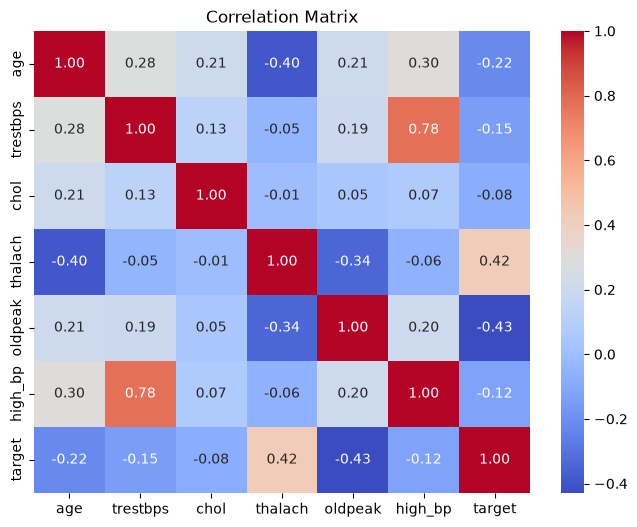

In [6]:
#-1 to +1 
#close to 1 = strong prositive relationship
#close to -1 = strong negative relationship
#0 = weak/ no relationship

corr_matrix=cleansed_DF[['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'high_bp', 'target']].corr()
print(corr_matrix)

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

Outlier Analysis

In [8]:
# Outlier Analysis using IQR Method

numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

for column in numerical_cols:
    
    Q1 = cleansed_DF[column].quantile(0.25)
    Q3 = cleansed_DF[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = cleansed_DF[
        (cleansed_DF[column] < lower) |
        (cleansed_DF[column] > upper)
    ]
    
    print(column, ":", len(outliers), "outliers")

age : 0 outliers
trestbps : 9 outliers
chol : 5 outliers
thalach : 1 outliers
oldpeak : 5 outliers


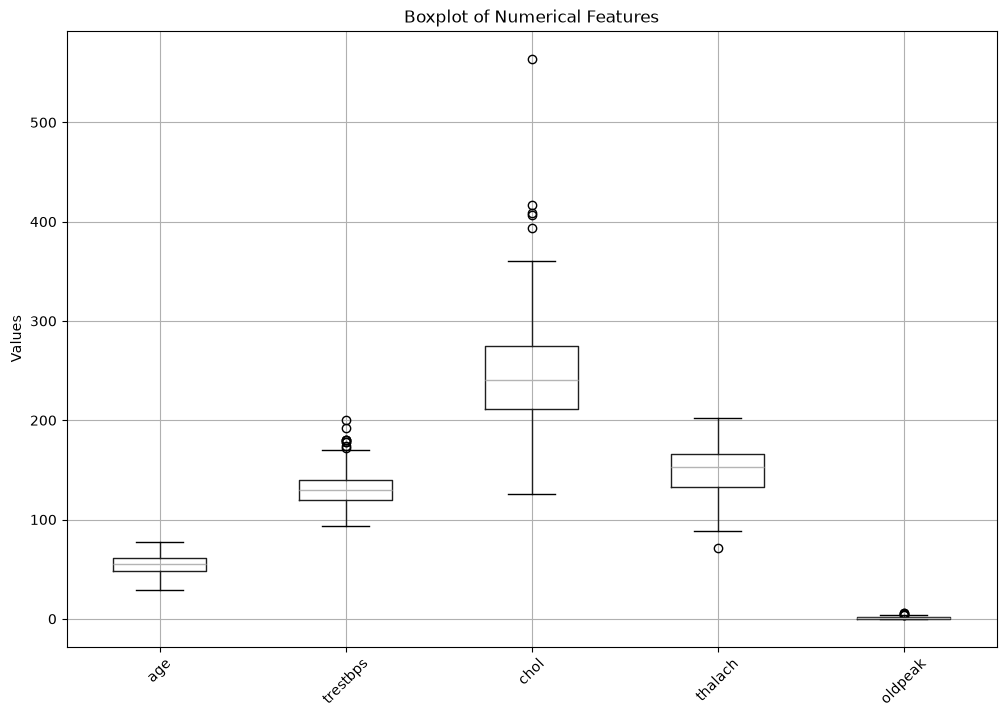

In [9]:
#Display boxplots for numerical columns to visualize outliers
# Boxplot of Numerical Features

cleansed_DF[numerical_cols].boxplot(figsize=(12, 8))

plt.title("Boxplot of Numerical Features")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.show()

In [ ]:
#Saving the cleansed Dataset 
cleansed_DF.to_csv('Final_heart_disease.csv', index=False)